# ⚡ Sesión 10-B: CNN 1D, TCN y Transformers para Series de Tiempo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_REPO/blob/main/notebook-semana10-B-cnn1d-tcn-transformers.ipynb)

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II
**Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Docente:** Msc. Jaime Antonio Huaytalla Pariona

---

### Objetivo
Explorar y comparar arquitecturas **no recurrentes** (CNN 1D, TCN, Transformers) para el análisis de series de tiempo, contrastándolas con los modelos LSTM/GRU del Notebook 10-A.

### Estructura del Notebook
| # | Nivel | Tema | Aplicación |
|---|---|---|---|
| 1 | 🟢 Básico | CNN 1D para clasificación de señales | **Clasificación** — comparación directa con BiLSTM |
| 2 | 🟡 Intermedio | TCN para pronóstico de consumo eléctrico | **Forecasting** — serie de alta frecuencia |
| 3 | 🔴 Avanzado | Transformer para pronóstico multivariado + Gran Comparativa | **Forecasting + Benchmark** de todas las arquitecturas |

> **Requisitos:** GPU T4 habilitada (Entorno de ejecución → Cambiar tipo de entorno → GPU T4)
> **Prerequisito:** Haber completado el Notebook 10-A (Series de Tiempo con RNN/LSTM/GRU)

In [1]:
# ============================================================
# 📦 Instalación e importaciones
# ============================================================
!pip install -q keras-tcn statsmodels

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split as tts
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error)
import time
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# Estilo
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f'TensorFlow: {tf.__version__}')
print(f'NumPy: {np.__version__}')

TensorFlow: 2.21.0
NumPy: 2.4.6


In [2]:
# ============================================================
# 🖥️ Verificación de GPU
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'✅ GPU disponible: {gpus[0].name}')
else:
    print('⚠️ No se detectó GPU. Ve a: Entorno de ejecución → Cambiar tipo de entorno → GPU T4')

✅ GPU disponible: /physical_device:GPU:0


## 📋 Recapitulación: ¿Por qué ir más allá de LSTM?

En el Notebook 10-A vimos que LSTM/GRU son poderosos, pero tienen **4 limitaciones prácticas**:

| Limitación | Impacto | Solución |
|---|---|---|
| **Procesamiento secuencial** | No se puede paralelizar → entrenamiento lento | CNN 1D, TCN, Transformer |
| **Memoria finita** | Información lejana se degrada | TCN (campo receptivo exponencial), Transformer (atención global) |
| **Cuello de botella del estado** | Todo el contexto comprimido en un vector fijo | Transformer (cada posición accede a todas) |
| **Costo O(T)** | Escala linealmente con longitud de secuencia | CNN 1D (paralelo), Transformer (O(T²) pero paralelo) |

### Línea temporal de evolución
```
RNN (1986) → LSTM (1997) → GRU (2014) → CNN 1D (2016) → Transformer (2017) → TCN (2018)
```

> 🎯 **Idea clave:** Las arquitecturas más nuevas procesan TODA la secuencia en paralelo, en vez de paso a paso.

In [3]:
# ============================================================
# 🛠️ Funciones auxiliares
# ============================================================

def create_sequences(data, window_size, horizon=1):
    '''Crea pares (X, y) con ventanas deslizantes.'''
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size:i + window_size + horizon, 0])
    X = np.array(X)
    y = np.array(y)
    if horizon == 1:
        y = y.flatten()
    return X, y


def evaluate_forecast(y_true, y_pred):
    '''Calcula MAE, RMSE y MAPE.'''
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape}


def plot_training_history(history, title='Entrenamiento'):
    '''Grafica loss y métricas.'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history['loss'], label='Train', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='Val', linewidth=2)
    axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{title} — Loss'); axes[0].legend()

    metric = 'mae' if 'mae' in history.history else 'accuracy'
    val_metric = f'val_{metric}'
    label = 'MAE' if metric == 'mae' else 'Accuracy'
    if metric in history.history:
        axes[1].plot(history.history[metric], label=f'Train {label}', linewidth=2)
        axes[1].plot(history.history[val_metric], label=f'Val {label}', linewidth=2)
        axes[1].set_xlabel('Época'); axes[1].set_ylabel(label)
        axes[1].set_title(f'{title} — {label}'); axes[1].legend()
    plt.tight_layout()
    plt.show()


COLORS = {
    'cnn1d': '#9C27B0',
    'tcn': '#00BCD4',
    'transformer': '#FF5722',
    'lstm': '#2196F3',
    'gru': '#FF9800',
    'bilstm': '#4CAF50',
    'hybrid': '#795548',
    'actual': '#263238',
    'naive': '#9E9E9E',
    'pred': '#E91E63'
}

print('✅ Funciones auxiliares cargadas')

✅ Funciones auxiliares cargadas


---

## 🎵 Ejemplo 1 (Básico): CNN 1D para Clasificación de Señales

**Objetivo:** Clasificar el mismo dataset de 5 tipos de señales del Notebook 10-A, pero usando CNN 1D en lugar de LSTM.

**¿Por qué CNN 1D para series de tiempo?**
La misma idea de CNN 2D (filtros que detectan patrones locales en imágenes) funciona sobre un eje temporal:

| Aspecto | CNN 2D (imágenes) | CNN 1D (secuencias) |
|---|---|---|
| **Entrada** | (alto, ancho, canales) | (timesteps, features) |
| **Filtro** | Kernel 2D: (3×3) | Kernel 1D: (tamaño,) |
| **Detecta** | Bordes, texturas | Picos, tendencias, patrones |
| **Keras** | `Conv2D(filters, kernel)` | `Conv1D(filters, kernel)` |

**Ventaja clave:** CNN 1D procesa TODA la secuencia en paralelo → 5-10x más rápida que LSTM.

**Dataset:** 5 tipos de señales sintéticas (5000 muestras, 128 timesteps) — mismo dataset del Notebook 10-A.

In [4]:
# ============================================================
# 🎵 Generación del dataset de señales (mismo que Notebook 10-A)
# ============================================================
np.random.seed(42)

N_SAMPLES = 1000
SEQ_LEN = 128
N_CLASSES = 5
NOISE_LEVEL = 0.05

class_names = ['Sinusoidal', 'Cuadrada', 'Diente de Sierra', 'Chirp', 'Ruido']
t = np.linspace(0, 1, SEQ_LEN)

signals, labels = [], []
for i in range(N_SAMPLES):
    freq = np.random.uniform(1, 3)
    phase = np.random.uniform(0, 2 * np.pi)

    # Clase 0: Sinusoidal
    s0 = np.sin(2 * np.pi * freq * t + phase)
    signals.append(s0 + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(0)

    # Clase 1: Cuadrada
    s1 = np.sign(np.sin(2 * np.pi * freq * t + phase))
    signals.append(s1 + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(1)

    # Clase 2: Diente de Sierra
    phase2 = np.random.uniform(0, 1)
    s2 = 2 * ((freq * t + phase2) % 1) - 1
    signals.append(s2 + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(2)

    # Clase 3: Chirp
    f0, f1 = np.random.uniform(0.5, 1.5), np.random.uniform(3, 6)
    s3 = np.sin(2 * np.pi * (f0 * t + (f1 - f0) * t**2 / 2))
    signals.append(s3 + np.random.normal(0, NOISE_LEVEL, SEQ_LEN))
    labels.append(3)

    # Clase 4: Ruido
    amplitude = np.random.uniform(0.5, 1.5)
    signals.append(np.random.normal(0, amplitude, SEQ_LEN))
    labels.append(4)

X_signals = np.array(signals)
y_signals = np.array(labels)

# Normalizar y reshape
scaler_sig = StandardScaler()
X_norm = scaler_sig.fit_transform(X_signals).reshape(-1, SEQ_LEN, 1)

# Split
X_train_sig, X_test_sig, y_train_sig, y_test_sig = tts(
    X_norm, y_signals, test_size=0.2, stratify=y_signals, random_state=42
)
y_train_oh = tf.keras.utils.to_categorical(y_train_sig, N_CLASSES)
y_test_oh = tf.keras.utils.to_categorical(y_test_sig, N_CLASSES)

print(f'Dataset: {X_signals.shape[0]} señales × {SEQ_LEN} timesteps')
print(f'Train: {X_train_sig.shape[0]} | Test: {X_test_sig.shape[0]}')

Dataset: 5000 señales × 128 timesteps
Train: 4000 | Test: 1000


### 🔧 Padding Causal — Concepto Crítico

En series de tiempo, existe un concepto que NO existe en imágenes: **la causalidad**.

```
padding='same'   →  Pad simétrico → ¡El filtro VE el futuro! ← VIOLA CAUSALIDAD
padding='causal'  →  Pad solo a la izquierda → Solo mira pasado + presente ← CORRECTO
```

**Regla:** Para **forecasting**, SIEMPRE usar `padding='causal'`. Para **clasificación** (tenemos toda la secuencia), `same` es aceptable.

En este ejemplo usaremos `same` porque estamos clasificando señales completas.

In [5]:
# ============================================================
# 🏗️ Modelo CNN 1D para clasificación
# ============================================================
tf.random.set_seed(42)

model_cnn1d = models.Sequential([
    # Bloque 1: filtros grandes para patrones amplios
    layers.Conv1D(64, kernel_size=7, activation='relu',
                  padding='same', input_shape=(SEQ_LEN, 1), name='conv1d_64'),
    layers.BatchNormalization(name='bn_1'),
    layers.MaxPooling1D(pool_size=2, name='pool_1'),

    # Bloque 2: filtros medios para patrones refinados
    layers.Conv1D(128, kernel_size=5, activation='relu',
                  padding='same', name='conv1d_128'),
    layers.BatchNormalization(name='bn_2'),
    layers.MaxPooling1D(pool_size=2, name='pool_2'),

    # Bloque 3: filtros pequeños para detalles
    layers.Conv1D(64, kernel_size=3, activation='relu',
                  padding='same', name='conv1d_64b'),
    layers.BatchNormalization(name='bn_3'),

    # Clasificación
    layers.GlobalAveragePooling1D(name='gap'),
    layers.Dense(64, activation='relu', name='dense_64'),
    layers.Dropout(0.3, name='dropout'),
    layers.Dense(N_CLASSES, activation='softmax', name='salida')
], name='CNN_1D_Classifier')

model_cnn1d.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn1d.summary()
print(f'\nParámetros: {model_cnn1d.count_params():,}')

Model: "CNN_1D_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_64 (Conv1D)              │ (None, 128, 64)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling1D)           │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_128 (Conv1D)             │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling1D)           │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_64b (Conv1D)             │ (None, 32, 64)         │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 32, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling1D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,749 (280.27 KB)

 Trainable params: 71,237 (278.27 KB)

 Non-trainable params: 512 (2.00 KB)


Parámetros: 71,749


Entrenando CNN 1D...
Epoch 1/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 28s 216ms/step - accuracy: 0.9062 - loss: 0.3450 - val_accuracy: 0.2800 - val_loss: 1.4643
Epoch 2/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step - accuracy: 0.9803 - loss: 0.0832 - val_accuracy: 0.2717 - val_loss: 2.1403
Epoch 3/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9868 - loss: 0.0515 - val_accuracy: 0.2850 - val_loss: 2.4856
Epoch 4/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9926 - loss: 0.0331 - val_accuracy: 0.3467 - val_loss: 2.6136
Epoch 5/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9938 - loss: 0.0263 - val_accuracy: 0.4683 - val_loss: 2.1317
Epoch 6/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9906 - loss: 0.0246 - val_accuracy: 0.5733 - val_loss: 1.0135
Epoch 7/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9950 - loss: 0.0168 - val_accuracy: 0.7667 - val_loss: 0.5560
Epoch 8/30
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9941 - loss: 0.0215 - val_acc

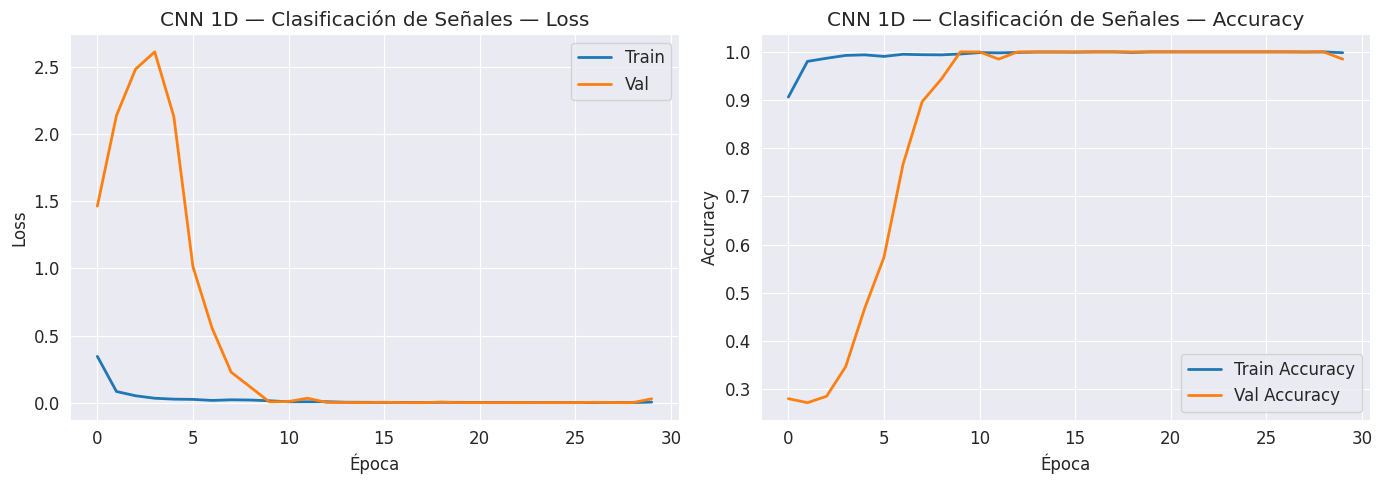

In [6]:
# ============================================================
# 🚀 Entrenamiento CNN 1D
# ============================================================
print('Entrenando CNN 1D...')
t0 = time.time()
hist_cnn1d = model_cnn1d.fit(
    X_train_sig, y_train_oh,
    epochs=30, batch_size=64,
    validation_split=0.15,
    callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=1)],
    verbose=1
)
time_cnn1d = time.time() - t0

loss_cnn, acc_cnn = model_cnn1d.evaluate(X_test_sig, y_test_oh, verbose=0)
print(f'\n⏱️ Tiempo: {time_cnn1d:.1f}s')
print(f'📊 Test Accuracy: {acc_cnn:.4f}')

plot_training_history(hist_cnn1d, 'CNN 1D — Clasificación de Señales')

Entrenando LSTM de referencia...
Entrenando BiLSTM de referencia...

COMPARACIÓN: CNN 1D vs LSTM vs BiLSTM — Clasificación de Señales
Modelo          Accuracy     Params       Tiempo (s)  
-----------------------------------------------------------------
CNN 1D          1.0000       71,749       58.4        
LSTM            0.9990       19,141       23.0        
BiLSTM          0.9850       38,085       10.6        


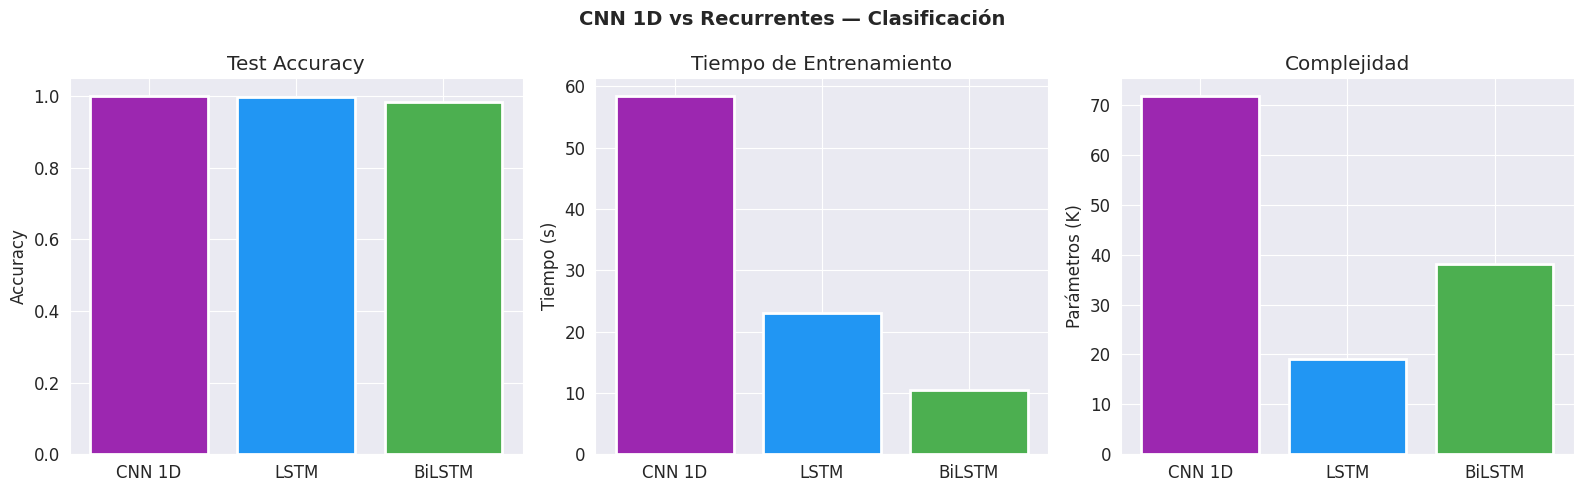

In [7]:
# ============================================================
# 📊 Comparación con LSTM/BiLSTM del Notebook 10-A
# ============================================================
tf.random.set_seed(42)

model_lstm_cls = models.Sequential([
    layers.LSTM(64, input_shape=(SEQ_LEN, 1)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(N_CLASSES, activation='softmax')
], name='LSTM_ref')
model_lstm_cls.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model_bilstm_cls = models.Sequential([
    layers.Bidirectional(layers.LSTM(64), input_shape=(SEQ_LEN, 1)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(N_CLASSES, activation='softmax')
], name='BiLSTM_ref')
model_bilstm_cls.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

cb = lambda: [callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0)]

print('Entrenando LSTM de referencia...')
t0 = time.time()
model_lstm_cls.fit(X_train_sig, y_train_oh, epochs=30, batch_size=64,
                   validation_split=0.15, callbacks=cb(), verbose=0)
time_lstm_cls = time.time() - t0
_, acc_lstm_cls = model_lstm_cls.evaluate(X_test_sig, y_test_oh, verbose=0)

print('Entrenando BiLSTM de referencia...')
t0 = time.time()
model_bilstm_cls.fit(X_train_sig, y_train_oh, epochs=30, batch_size=64,
                     validation_split=0.15, callbacks=cb(), verbose=0)
time_bilstm_cls = time.time() - t0
_, acc_bilstm_cls = model_bilstm_cls.evaluate(X_test_sig, y_test_oh, verbose=0)

print('\n' + '=' * 65)
print('COMPARACIÓN: CNN 1D vs LSTM vs BiLSTM — Clasificación de Señales')
print('=' * 65)
print(f'{"Modelo":<15} {"Accuracy":<12} {"Params":<12} {"Tiempo (s)":<12}')
print('-' * 65)
models_data = [
    ('CNN 1D', acc_cnn, model_cnn1d.count_params(), time_cnn1d),
    ('LSTM', acc_lstm_cls, model_lstm_cls.count_params(), time_lstm_cls),
    ('BiLSTM', acc_bilstm_cls, model_bilstm_cls.count_params(), time_bilstm_cls),
]
for name, acc, p, t_ in models_data:
    print(f'{name:<15} {acc:<12.4f} {p:<12,} {t_:<12.1f}')
print('=' * 65)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
names = ['CNN 1D', 'LSTM', 'BiLSTM']
accs = [acc_cnn, acc_lstm_cls, acc_bilstm_cls]
times_list = [time_cnn1d, time_lstm_cls, time_bilstm_cls]
params_list = [model_cnn1d.count_params(), model_lstm_cls.count_params(),
               model_bilstm_cls.count_params()]
bar_colors = [COLORS['cnn1d'], COLORS['lstm'], COLORS['bilstm']]

for ax, vals, ylabel, title in zip(axes,
    [accs, times_list, [p/1000 for p in params_list]],
    ['Accuracy', 'Tiempo (s)', 'Parámetros (K)'],
    ['Test Accuracy', 'Tiempo de Entrenamiento', 'Complejidad']):
    bars = ax.bar(names, vals, color=bar_colors, edgecolor='white', linewidth=2)
    ax.set_ylabel(ylabel); ax.set_title(title)

plt.suptitle('CNN 1D vs Recurrentes — Clasificación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Shape de los filtros: (7, 1, 64)
  → 64 filtros de tamaño 7


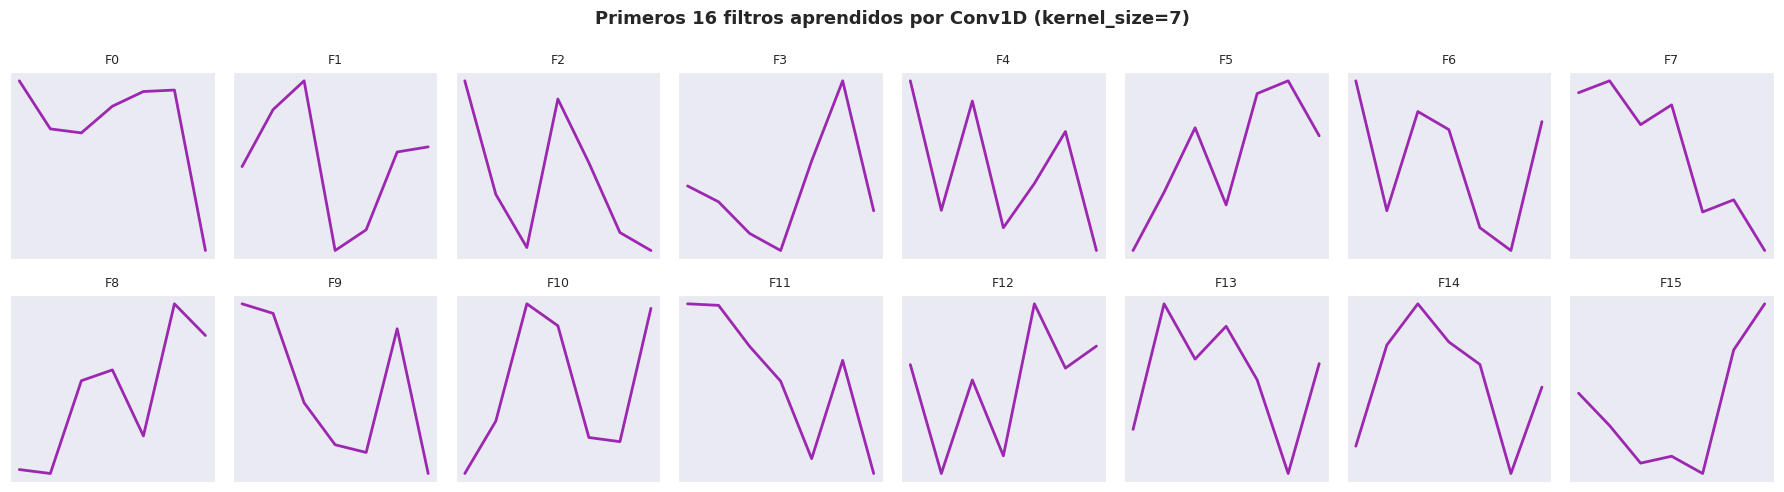

💡 Cada filtro detecta un patrón temporal diferente:
   • Algunos son detectores de picos (alta frecuencia)
   • Otros detectan tendencias (suben o bajan)
   • Algunos son paso-bajo (suaves, detectan cambios lentos)


In [8]:
# ============================================================
# 🔍 Visualización de filtros CNN 1D aprendidos
# ============================================================
conv_weights = model_cnn1d.layers[0].get_weights()[0]  # (kernel, 1, filters)
print(f'Shape de los filtros: {conv_weights.shape}')
print(f'  → {conv_weights.shape[2]} filtros de tamaño {conv_weights.shape[0]}')

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for i in range(16):
    ax = axes[i // 8, i % 8]
    ax.plot(conv_weights[:, 0, i], color=COLORS['cnn1d'], linewidth=2)
    ax.set_title(f'F{i}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle('Primeros 16 filtros aprendidos por Conv1D (kernel_size=7)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('💡 Cada filtro detecta un patrón temporal diferente:')
print('   • Algunos son detectores de picos (alta frecuencia)')
print('   • Otros detectan tendencias (suben o bajan)')
print('   • Algunos son paso-bajo (suaves, detectan cambios lentos)')

### 💡 Conclusiones del Ejemplo 1

1. **CNN 1D es competitiva con BiLSTM** en clasificación de señales, y significativamente más rápida.
2. **Paralelismo total**: Los filtros convolucionales procesan toda la secuencia de una vez.
3. **Los filtros aprendidos son interpretables**: cada filtro detecta un patrón temporal específico.
4. **Limitación**: El campo receptivo depende del tamaño del kernel y la profundidad. Para secuencias muy largas, necesitamos dilatación → TCN.

> ⚡ **Transición:** CNN 1D tiene un campo receptivo limitado. ¿Qué pasa si necesitamos ver 200+ pasos atrás? → Convoluciones dilatadas (TCN).

---

## 📈 Ejemplo 2 (Intermedio): TCN para Pronóstico de Consumo Eléctrico

**Objetivo:** Usar una Temporal Convolutional Network (TCN) para pronóstico de series de tiempo, mostrando la ventaja de las convoluciones dilatadas.

**¿Qué es una TCN?**

El problema de CNN 1D: para ver 200 pasos atrás necesitaríamos ~100 capas de Conv1D(kernel=3). La TCN resuelve esto con **dilatación creciente**:

```
Dilatación = 1:  [* . * . *]           → ve 3 pasos
Dilatación = 2:  [* . . . * . . . *]   → ve 5 pasos (salta 1)
Dilatación = 4:  [* . . . . . . . *]   → ve 9 pasos (salta 3)
Dilatación = 8:  [* . . . . . . . . . . . . . . . *]  → ve 17 pasos
```

Con solo **6 capas** (dilatación 1,2,4,8,16,32) una TCN puede ver **190 pasos atrás**. Un LSTM necesitaría procesar los 190 pasos secuencialmente.

**Dataset:** Consumo eléctrico horario — Serie sintética realista con patrones diarios y semanales.

**Tarea:** Pronóstico multi-horizonte (predecir 24 horas adelante)

Serie de consumo eléctrico: 17,520 horas (2.0 años)
Rango: [1.33, 3.09] kW


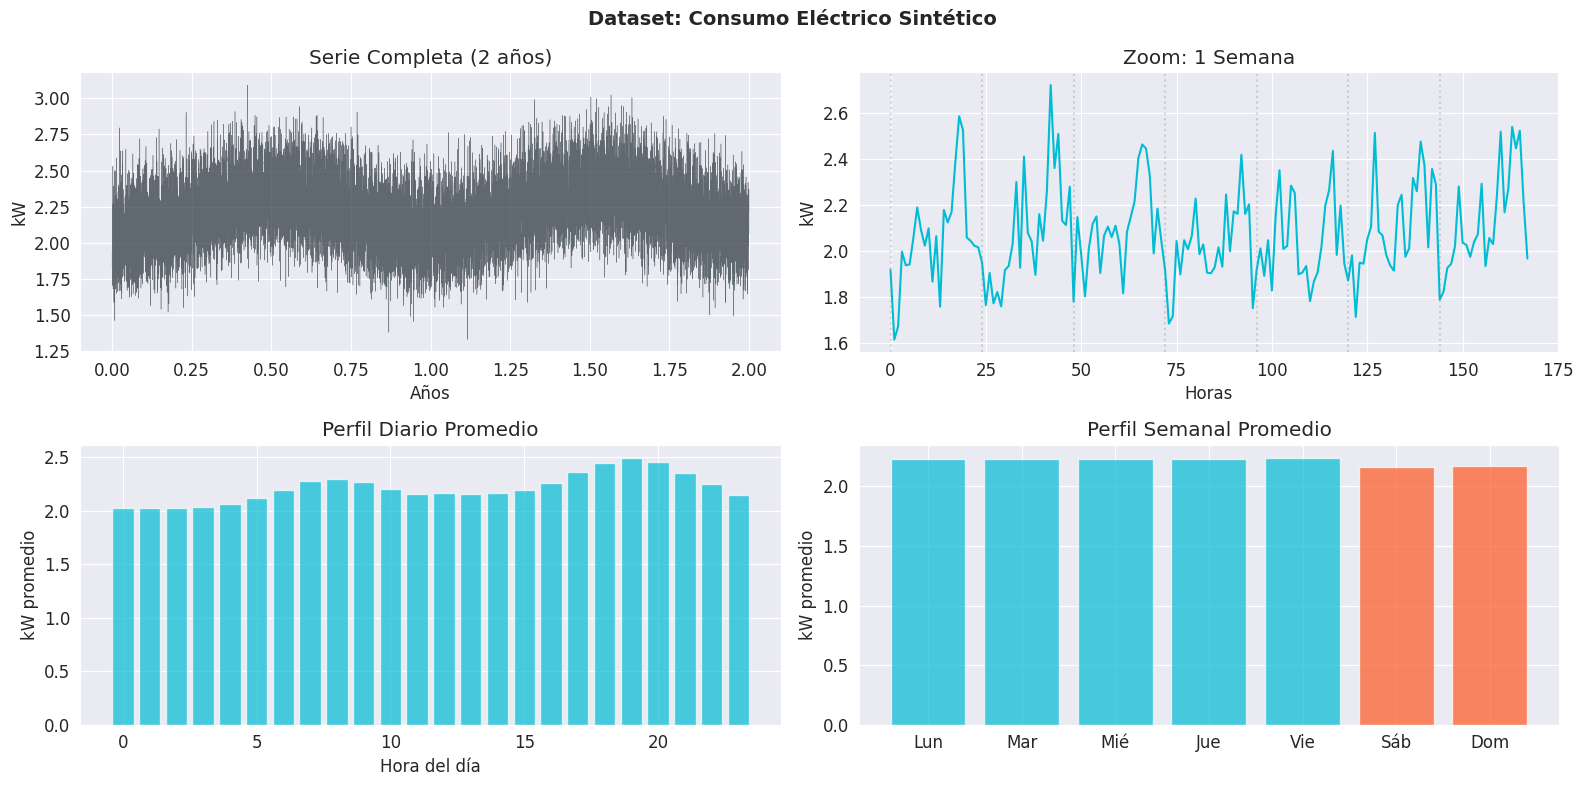

In [9]:
# ============================================================
# 📥 Generación de dataset de consumo eléctrico sintético realista
# ============================================================
np.random.seed(42)

N_HOURS = 24 * 365 * 2  # 2 años de datos horarios
hours = np.arange(N_HOURS)

# Componente diaria: picos mañana y noche
hour_of_day = hours % 24
daily_pattern = (
    0.3 * np.exp(-0.5 * ((hour_of_day - 8) / 2) ** 2) +
    0.5 * np.exp(-0.5 * ((hour_of_day - 19) / 2.5) ** 2) +
    0.1 * np.exp(-0.5 * ((hour_of_day - 13) / 1.5) ** 2)
)

# Componente semanal
day_of_week = (hours // 24) % 7
weekly_factor = np.where(day_of_week >= 5, 0.7, 1.0)

# Estacionalidad anual + tendencia
day_of_year = (hours / 24) % 365.25
annual = 0.15 * np.sin(2 * np.pi * day_of_year / 365.25 - np.pi/2)
trend = 0.05 * hours / N_HOURS

# Combinar
consumption = 2.0 + daily_pattern * weekly_factor + annual + trend
consumption += np.random.normal(0, 0.15, N_HOURS)
consumption = np.clip(consumption, 0.5, None)

print(f'Serie de consumo eléctrico: {N_HOURS:,} horas ({N_HOURS/24/365:.1f} años)')
print(f'Rango: [{consumption.min():.2f}, {consumption.max():.2f}] kW')

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

axes[0, 0].plot(hours / (24*365), consumption, linewidth=0.3,
                color=COLORS['actual'], alpha=0.7)
axes[0, 0].set_xlabel('Años'); axes[0, 0].set_ylabel('kW')
axes[0, 0].set_title('Serie Completa (2 años)')

week_start = 24 * 30
axes[0, 1].plot(consumption[week_start:week_start+168],
                color=COLORS['tcn'], linewidth=1.5)
axes[0, 1].set_xlabel('Horas'); axes[0, 1].set_ylabel('kW')
axes[0, 1].set_title('Zoom: 1 Semana')
for d in range(7):
    axes[0, 1].axvline(x=d*24, color='gray', linestyle=':', alpha=0.3)

daily_avg = np.array([consumption[hour_of_day == h].mean() for h in range(24)])
axes[1, 0].bar(range(24), daily_avg, color=COLORS['tcn'], alpha=0.7)
axes[1, 0].set_xlabel('Hora del día'); axes[1, 0].set_ylabel('kW promedio')
axes[1, 0].set_title('Perfil Diario Promedio')

weekly_avg = np.array([consumption[day_of_week == d].mean() for d in range(7)])
day_names = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
colors_w = [COLORS['tcn'] if d < 5 else COLORS['transformer'] for d in range(7)]
axes[1, 1].bar(day_names, weekly_avg, color=colors_w, alpha=0.7)
axes[1, 1].set_ylabel('kW promedio')
axes[1, 1].set_title('Perfil Semanal Promedio')

plt.suptitle('Dataset: Consumo Eléctrico Sintético', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# 🔧 Preprocesamiento para pronóstico
# ============================================================
split_idx = int(len(consumption) * 0.8)
train_elec = consumption[:split_idx]
test_elec = consumption[split_idx:]

scaler_elec = MinMaxScaler()
train_scaled = scaler_elec.fit_transform(train_elec.reshape(-1, 1)).flatten()
test_scaled = scaler_elec.transform(test_elec.reshape(-1, 1)).flatten()

WINDOW_ELEC = 168  # 1 semana
HORIZON = 24       # Predecir 24 horas

X_train_e, y_train_e = create_sequences(train_scaled, WINDOW_ELEC, HORIZON)
X_test_e, y_test_e = create_sequences(test_scaled, WINDOW_ELEC, HORIZON)

print(f'Ventana: {WINDOW_ELEC}h (1 semana) → Horizonte: {HORIZON}h (1 día)')
print(f'X_train: {X_train_e.shape} | y_train: {y_train_e.shape}')
print(f'X_test:  {X_test_e.shape}  | y_test:  {y_test_e.shape}')

Ventana: 168h (1 semana) → Horizonte: 24h (1 día)
X_train: (13825, 168, 1) | y_train: (13825, 24)
X_test:  (3313, 168, 1)  | y_test:  (3313, 24)


### 🏗️ Arquitectura TCN — Bloque por Bloque

Un **bloque TCN** combina:
1. **Conv1D causal dilatada** — filtros que solo miran el pasado
2. **BatchNormalization** — estabiliza el entrenamiento
3. **ReLU + Dropout** — no linealidad + regularización
4. **Conexión residual** — permite entrenar redes profundas

La clave es la **dilatación exponencial** (1, 2, 4, 8, 16, 32, ...):

```
Campo receptivo = 1 + n_capas × (kernel_size - 1) × (2^n_capas - 1)
```

Con 6 capas de kernel=3: campo receptivo = 1 + 6 × 2 × 63 = **757 pasos**

In [11]:
# ============================================================
# 🏗️ Modelo TCN usando keras-tcn
# ============================================================
from tcn import TCN

tf.random.set_seed(42)

model_tcn = models.Sequential([
    TCN(
        nb_filters=64,
        kernel_size=3,
        nb_stacks=1,
        dilations=[1, 2, 4, 8, 16, 32],
        padding='causal',
        use_skip_connections=True,
        dropout_rate=0.2,
        return_sequences=False,
        input_shape=(WINDOW_ELEC, 1),
        name='tcn_block'
    ),
    layers.Dense(64, activation='relu', name='dense_64'),
    layers.Dropout(0.2, name='dropout'),
    layers.Dense(HORIZON, name='salida')
], name='TCN_Forecaster')

model_tcn.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_tcn.summary()

tcn_params = model_tcn.count_params()
print(f'\nCampo receptivo teórico: {1 + 2*(3-1)*(1+2+4+8+16+32)} pasos')
print(f'Parámetros totales: {tcn_params:,}')

Model: "TCN_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn_block (TCN)                 │ (None, 64)             │       136,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 141,976 (554.59 KB)

 Trainable params: 141,976 (554.59 KB)

 Non-trainable params: 0 (0.00 B)


Campo receptivo teórico: 253 pasos
Parámetros totales: 141,976


In [12]:
# ============================================================
# 🏗️ Modelo LSTM de referencia (mismo problema)
# ============================================================
tf.random.set_seed(42)

model_lstm_elec = models.Sequential([
    layers.LSTM(128, return_sequences=True, input_shape=(WINDOW_ELEC, 1)),
    layers.Dropout(0.3),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(HORIZON)
], name='LSTM_Forecaster')

model_lstm_elec.compile(optimizer='adam', loss='mse', metrics=['mae'])
lstm_elec_params = model_lstm_elec.count_params()
print(f'LSTM params: {lstm_elec_params:,}')
print(f'TCN params:  {tcn_params:,}')

LSTM params: 121,688
TCN params:  141,976


In [13]:
# ============================================================
# 🚀 Entrenamiento de TCN y LSTM
# ============================================================
cb_fn = lambda: [
    callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

print('🔵 Entrenando TCN...')
t0 = time.time()
hist_tcn = model_tcn.fit(X_train_e, y_train_e, epochs=30, batch_size=64,
                         validation_split=0.15, callbacks=cb_fn(), verbose=0)
time_tcn = time.time() - t0
print(f'   ⏱️ {time_tcn:.1f}s | Mejor val_loss: {min(hist_tcn.history["val_loss"]):.6f}')

print('🟠 Entrenando LSTM...')
t0 = time.time()
hist_lstm_e = model_lstm_elec.fit(X_train_e, y_train_e, epochs=30, batch_size=64,
                                  validation_split=0.15, callbacks=cb_fn(), verbose=0)
time_lstm_e = time.time() - t0
print(f'   ⏱️ {time_lstm_e:.1f}s | Mejor val_loss: {min(hist_lstm_e.history["val_loss"]):.6f}')

print(f'\n⚡ TCN fue {time_lstm_e/time_tcn:.1f}x más rápido que LSTM')

🔵 Entrenando TCN...
   ⏱️ 139.5s | Mejor val_loss: 0.018352
🟠 Entrenando LSTM...
   ⏱️ 64.9s | Mejor val_loss: 0.008376

⚡ TCN fue 0.5x más rápido que LSTM


PRONÓSTICO DE CONSUMO ELÉCTRICO (24h adelante)
Modelo     MAE (kW)     RMSE (kW)    Params       Tiempo (s)  
------------------------------------------------------------
TCN        0.1621       0.2036       141,976      139.5       
LSTM       0.1257       0.1571       121,688      64.9        


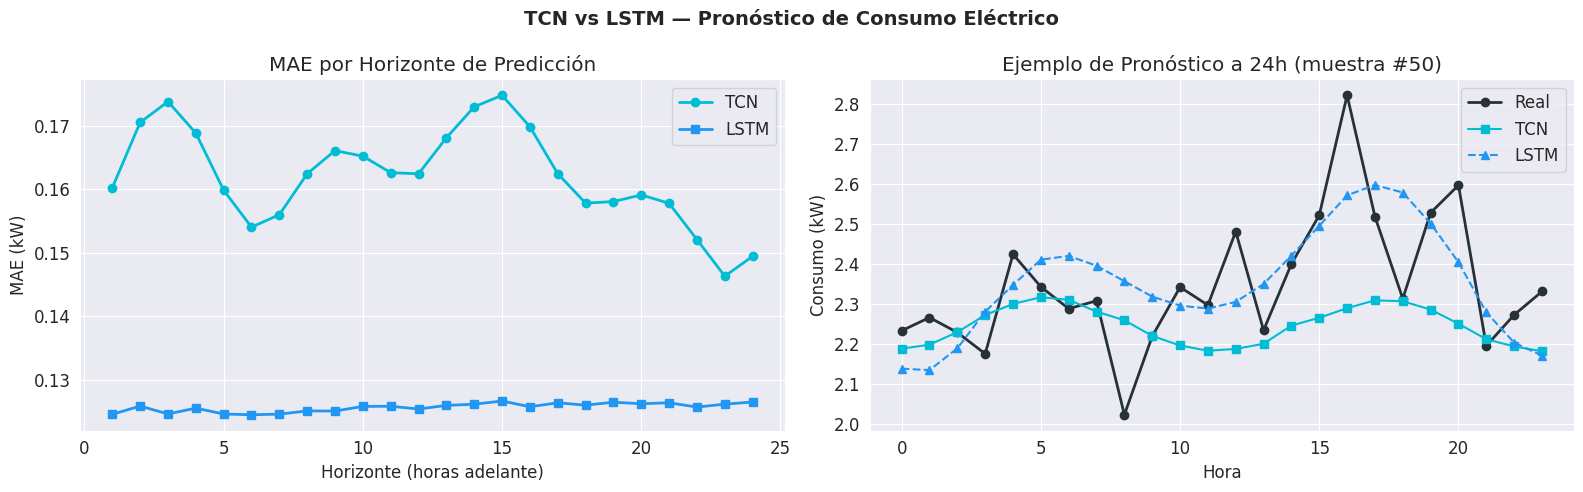

In [14]:
# ============================================================
# 📏 Evaluación TCN vs LSTM — Pronóstico 24h
# ============================================================
pred_tcn = model_tcn.predict(X_test_e, verbose=0)
pred_lstm_e = model_lstm_elec.predict(X_test_e, verbose=0)

def denorm_elec(values):
    return scaler_elec.inverse_transform(values.reshape(-1, 1)).flatten()

# MAE por horizonte
metrics_per_h_tcn, metrics_per_h_lstm = [], []
for h in range(HORIZON):
    y_real_h = denorm_elec(y_test_e[:, h])
    metrics_per_h_tcn.append(mean_absolute_error(y_real_h, denorm_elec(pred_tcn[:, h])))
    metrics_per_h_lstm.append(mean_absolute_error(y_real_h, denorm_elec(pred_lstm_e[:, h])))

# Global
y_test_flat = denorm_elec(y_test_e.flatten())
m_tcn = evaluate_forecast(y_test_flat, denorm_elec(pred_tcn.flatten()))
m_lstm_e = evaluate_forecast(y_test_flat, denorm_elec(pred_lstm_e.flatten()))

print('=' * 60)
print('PRONÓSTICO DE CONSUMO ELÉCTRICO (24h adelante)')
print('=' * 60)
print(f'{"Modelo":<10} {"MAE (kW)":<12} {"RMSE (kW)":<12} {"Params":<12} {"Tiempo (s)":<12}')
print('-' * 60)
print(f'{"TCN":<10} {m_tcn["MAE"]:<12.4f} {m_tcn["RMSE"]:<12.4f} {tcn_params:<12,} {time_tcn:<12.1f}')
print(f'{"LSTM":<10} {m_lstm_e["MAE"]:<12.4f} {m_lstm_e["RMSE"]:<12.4f} {lstm_elec_params:<12,} {time_lstm_e:<12.1f}')
print('=' * 60)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(range(1, HORIZON+1), metrics_per_h_tcn, 'o-',
             color=COLORS['tcn'], linewidth=2, label='TCN')
axes[0].plot(range(1, HORIZON+1), metrics_per_h_lstm, 's-',
             color=COLORS['lstm'], linewidth=2, label='LSTM')
axes[0].set_xlabel('Horizonte (horas adelante)')
axes[0].set_ylabel('MAE (kW)')
axes[0].set_title('MAE por Horizonte de Predicción')
axes[0].legend()

sample = 50
y_rs = denorm_elec(y_test_e[sample])
p_tcn_s = denorm_elec(pred_tcn[sample])
p_lstm_s = denorm_elec(pred_lstm_e[sample])
axes[1].plot(range(HORIZON), y_rs, 'o-', color=COLORS['actual'], linewidth=2, label='Real')
axes[1].plot(range(HORIZON), p_tcn_s, 's-', color=COLORS['tcn'], linewidth=1.5, label='TCN')
axes[1].plot(range(HORIZON), p_lstm_s, '^--', color=COLORS['lstm'], linewidth=1.5, label='LSTM')
axes[1].set_xlabel('Hora'); axes[1].set_ylabel('Consumo (kW)')
axes[1].set_title(f'Ejemplo de Pronóstico a 24h (muestra #{sample})')
axes[1].legend()

plt.suptitle('TCN vs LSTM — Pronóstico de Consumo Eléctrico',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 💡 Conclusiones del Ejemplo 2

1. **TCN es más rápida que LSTM** para secuencias largas, gracias al paralelismo de las convoluciones.
2. **Las convoluciones dilatadas** permiten un campo receptivo enorme (700+ pasos) con pocas capas.
3. **El MAE crece con el horizonte** — es natural: predecir más lejos es más difícil.
4. **Padding causal** es obligatorio para forecasting: sin él, el modelo "haría trampa" viendo datos futuros.

> ⚡ **Siguiente:** ¿Y si cada punto pudiera "mirar" directamente a CUALQUIER otro punto? → Transformers.

---

## 🧠 Ejemplo 3 (Avanzado): Transformer para Pronóstico + Gran Comparativa

**Objetivo:** Implementar un Transformer desde cero para pronóstico de series de tiempo y ejecutar una **comparativa final** entre todas las arquitecturas.

**Self-Attention: La idea revolucionaria**

```
LSTM:        paso_1 → paso_2 → paso_3 → ... → paso_100  (99 estados intermedios)
Transformer: paso_1 ←→ paso_100  (acceso directo, distancia = 1)
```

**Componentes clave:**
- **Q (Query):** "¿Qué estoy buscando?"
- **K (Key):** "¿Qué tengo para ofrecer?"
- **V (Value):** "Este es mi contenido"
- **Fórmula:** Attention(Q,K,V) = softmax(QK^T / √d_k) · V

**Dataset:** Jena Climate (multivariado) — para comparación directa con Notebook 10-A.

In [16]:
# ============================================================
# 📥 Cargar Jena Climate
# ============================================================
import os

zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    extract=True
)
# Al extraer el archivo, se crea una carpeta. Apuntamos al archivo CSV real dentro de ella
extracted_dir = zip_path.replace('.zip', '')
csv_path = os.path.join(extracted_dir, 'jena_climate_2009_2016.csv')
df_jena = pd.read_csv(csv_path)

features = ['T (degC)', 'p (mbar)', 'rh (%)', 'wv (m/s)']
multi_data = df_jena[features].values[::6]

split_idx = int(len(multi_data) * 0.8)
train_jena = multi_data[:split_idx]
test_jena = multi_data[split_idx:]

scaler_jena = MinMaxScaler()
train_jena_s = scaler_jena.fit_transform(train_jena)
test_jena_s = scaler_jena.transform(test_jena)

WINDOW_T = 72
X_train_t, y_train_t = create_sequences(train_jena_s, WINDOW_T, 1)
X_test_t, y_test_t = create_sequences(test_jena_s, WINDOW_T, 1)

temp_min = scaler_jena.data_min_[0]
temp_max = scaler_jena.data_max_[0]

print(f'Jena Climate (4 features, horario):')
print(f'  X_train: {X_train_t.shape} | X_test: {X_test_t.shape}')

Jena Climate (4 features, horario):
  X_train: (56001, 72, 4) | X_test: (13947, 72, 4)


In [17]:
# ============================================================
# 🏗️ Transformer Block — Implementación desde cero
# ============================================================

class TransformerBlock(layers.Layer):
    '''Bloque Transformer con Multi-Head Self-Attention.

    Componentes:
    1. Multi-Head Attention (causal mask para forecasting)
    2. Add & Norm (conexión residual + LayerNorm)
    3. Feed-Forward Network
    4. Add & Norm
    '''
    def __init__(self, d_model, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.att = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=d_model // num_heads
        )
        self.ffn = models.Sequential([
            layers.Dense(ff_dim, activation='relu'),
            layers.Dense(d_model)
        ])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False):
        seq_len = tf.shape(x)[1]
        causal_mask = tf.linalg.band_part(
            tf.ones((seq_len, seq_len)), -1, 0
        )
        attn = self.att(x, x, attention_mask=causal_mask)
        attn = self.drop1(attn, training=training)
        x = self.norm1(x + attn)

        ffn_out = self.ffn(x)
        ffn_out = self.drop2(ffn_out, training=training)
        return self.norm2(x + ffn_out)


class PositionalEncoding(layers.Layer):
    '''Encoding posicional sinusoidal.'''
    def __init__(self, max_len=5000, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len

    def build(self, input_shape):
        d_model = input_shape[-1]
        pe = np.zeros((self.max_len, d_model))
        pos = np.arange(self.max_len)[:, np.newaxis]
        div = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))
        pe[:, 0::2] = np.sin(pos * div)
        pe[:, 1::2] = np.cos(pos * div[:d_model // 2])
        self.pe = tf.constant(pe[np.newaxis, :, :], dtype=tf.float32)
        super().build(input_shape)

    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]

print('✅ TransformerBlock y PositionalEncoding definidos')

✅ TransformerBlock y PositionalEncoding definidos


In [18]:
# ============================================================
# 🏗️ Modelo Transformer completo
# ============================================================
tf.random.set_seed(42)

D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
NUM_BLOCKS = 2

inputs = layers.Input(shape=(WINDOW_T, len(features)))
x = layers.Dense(D_MODEL)(inputs)
x = PositionalEncoding(max_len=WINDOW_T)(x)
x = layers.Dropout(0.1)(x)

for i in range(NUM_BLOCKS):
    x = TransformerBlock(D_MODEL, NUM_HEADS, FF_DIM, dropout=0.1,
                          name=f'transformer_block_{i}')(x)

x = x[:, -1, :]  # Última posición (many-to-one)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1)(x)

model_transformer = models.Model(inputs, outputs, name='Transformer_Forecaster')
model_transformer.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_transformer.summary()

trans_params = model_transformer.count_params()
print(f'\nParámetros: {trans_params:,}')
print(f'Heads: {NUM_HEADS} (cada head atiende a d_k={D_MODEL//NUM_HEADS} dims)')

Model: "Transformer_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 72, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 72, 64)         │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_encoding             │ (None, 72, 64)         │             0 │
│ (PositionalEncoding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_0             │ (None, 72, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 72, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ get_item (GetItem)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,377 (271.00 KB)

 Trainable params: 69,377 (271.00 KB)

 Non-trainable params: 0 (0.00 B)


Parámetros: 69,377
Heads: 4 (cada head atiende a d_k=16 dims)


🔴 Entrenando Transformer...
   ⏱️ 119.3s | Mejor val_loss: 0.000210


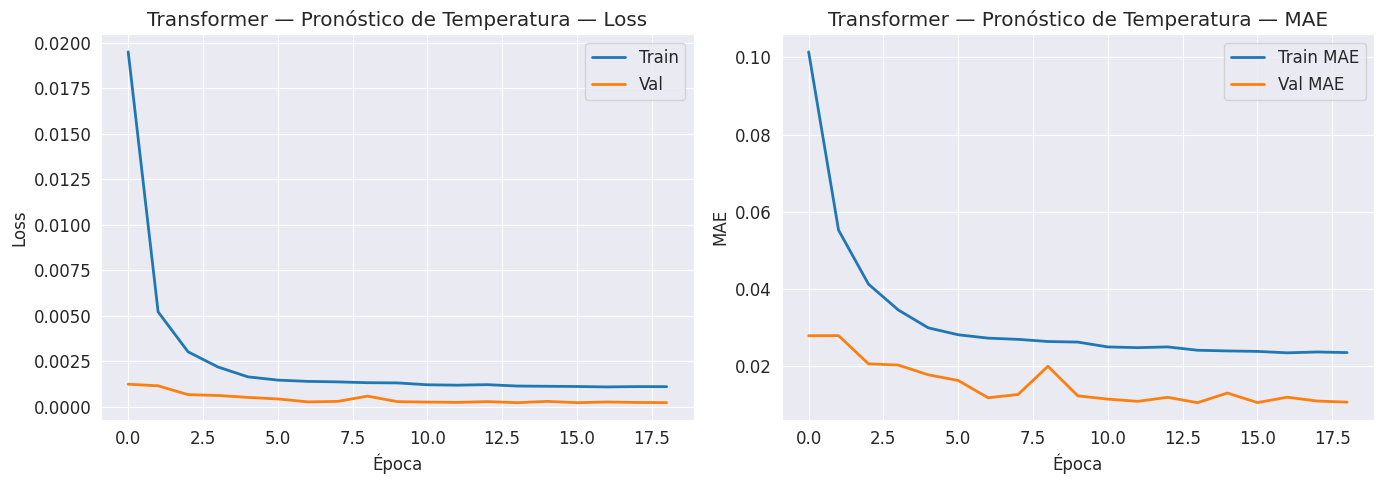

In [19]:
# ============================================================
# 🚀 Entrenamiento del Transformer
# ============================================================
print('🔴 Entrenando Transformer...')
t0 = time.time()
hist_trans = model_transformer.fit(
    X_train_t, y_train_t,
    epochs=30, batch_size=64,
    validation_split=0.15,
    callbacks=[
        callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
        callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
    ],
    verbose=0
)
time_trans = time.time() - t0
print(f'   ⏱️ {time_trans:.1f}s | Mejor val_loss: {min(hist_trans.history["val_loss"]):.6f}')

plot_training_history(hist_trans, 'Transformer — Pronóstico de Temperatura')

### 🏗️ Arquitectura Híbrida Bonus: CNN-LSTM

Combinar CNN 1D para patrones locales + LSTM para dependencias globales:

```
Entrada → Conv1D (patrones locales) → MaxPool (reduce secuencia) → LSTM (dependencias largas) → Dense
```

**¿Por qué funciona?** CNN reduce la longitud de la secuencia (via pooling) antes de pasarla al LSTM.

In [20]:
# ============================================================
# 🏗️ Modelos para la Gran Comparativa
# ============================================================
tf.random.set_seed(42)

# CNN 1D forecasting (causal)
model_cnn1d_fc = models.Sequential([
    layers.Conv1D(64, 7, activation='relu', padding='causal',
                  input_shape=(WINDOW_T, len(features))),
    layers.Conv1D(64, 5, activation='relu', padding='causal'),
    layers.Conv1D(32, 3, activation='relu', padding='causal'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
], name='CNN1D_FC')
model_cnn1d_fc.compile(optimizer='adam', loss='mse', metrics=['mae'])

# GRU Stacked
model_gru_fc = models.Sequential([
    layers.GRU(128, return_sequences=True, input_shape=(WINDOW_T, len(features))),
    layers.Dropout(0.3),
    layers.GRU(64),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
], name='GRU_FC')
model_gru_fc.compile(optimizer='adam', loss='mse', metrics=['mae'])

# LSTM Stacked
model_lstm_fc = models.Sequential([
    layers.LSTM(128, return_sequences=True, input_shape=(WINDOW_T, len(features))),
    layers.Dropout(0.3),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
], name='LSTM_FC')
model_lstm_fc.compile(optimizer='adam', loss='mse', metrics=['mae'])

# TCN
from tcn import TCN
model_tcn_fc = models.Sequential([
    TCN(nb_filters=64, kernel_size=3, dilations=[1, 2, 4, 8, 16],
        padding='causal', dropout_rate=0.2, return_sequences=False,
        input_shape=(WINDOW_T, len(features))),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
], name='TCN_FC')
model_tcn_fc.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Híbrido CNN-LSTM
model_hybrid = models.Sequential([
    layers.Conv1D(64, 5, activation='relu', padding='causal',
                  input_shape=(WINDOW_T, len(features))),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(32, 3, activation='relu', padding='causal'),
    layers.MaxPooling1D(pool_size=2),
    layers.LSTM(64),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1)
], name='CNN_LSTM_Hybrid')
model_hybrid.compile(optimizer='adam', loss='mse', metrics=['mae'])

all_models = {
    'CNN 1D': model_cnn1d_fc, 'LSTM': model_lstm_fc, 'GRU': model_gru_fc,
    'TCN': model_tcn_fc, 'Transformer': model_transformer, 'CNN-LSTM': model_hybrid
}

print('Parámetros por modelo:')
print('-' * 40)
for name, m in all_models.items():
    print(f'  {name:<15} → {m.count_params():>8,}')

Parámetros por modelo:
----------------------------------------
  CNN 1D          →   29,665
  LSTM            →  119,617
  GRU             →   90,817
  TCN             →  114,433
  Transformer     →   69,377
  CNN-LSTM        →   34,465


In [21]:
# ============================================================
# 🚀 Gran Comparativa — Entrenamiento
# ============================================================
benchmark_results = {}

# Transformer ya entrenado
pred_trans = model_transformer.predict(X_test_t, verbose=0).flatten()
pred_trans_real = pred_trans * (temp_max - temp_min) + temp_min
y_test_real = y_test_t * (temp_max - temp_min) + temp_min
m_trans = evaluate_forecast(y_test_real, pred_trans_real)
benchmark_results['Transformer'] = {
    'mae': m_trans['MAE'], 'rmse': m_trans['RMSE'],
    'params': model_transformer.count_params(),
    'time': time_trans, 'pred': pred_trans_real
}
print(f'✅ Transformer: MAE={m_trans["MAE"]:.4f}°C')

models_to_train = {
    'CNN 1D': model_cnn1d_fc, 'LSTM': model_lstm_fc,
    'GRU': model_gru_fc, 'TCN': model_tcn_fc, 'CNN-LSTM': model_hybrid
}

for name, model in models_to_train.items():
    tf.random.set_seed(42)
    print(f'Entrenando {name}...')
    t0 = time.time()
    model.fit(X_train_t, y_train_t, epochs=30, batch_size=64,
              validation_split=0.15, verbose=0,
              callbacks=[
                  callbacks.EarlyStopping(patience=5, restore_best_weights=True, verbose=0),
                  callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
              ])
    elapsed = time.time() - t0
    pred = model.predict(X_test_t, verbose=0).flatten()
    pred_real = pred * (temp_max - temp_min) + temp_min
    metrics = evaluate_forecast(y_test_real, pred_real)
    benchmark_results[name] = {
        'mae': metrics['MAE'], 'rmse': metrics['RMSE'],
        'params': model.count_params(), 'time': elapsed, 'pred': pred_real
    }
    print(f'   ✅ MAE={metrics["MAE"]:.4f}°C | {elapsed:.1f}s')

print('\n🏁 Todos los modelos entrenados.')

✅ Transformer: MAE=0.6366°C
Entrenando CNN 1D...
   ✅ MAE=1.2248°C | 106.3s
Entrenando LSTM...
   ✅ MAE=1.7836°C | 54.1s
Entrenando GRU...
   ✅ MAE=0.5406°C | 222.0s
Entrenando TCN...
   ✅ MAE=11.4074°C | 167.4s
Entrenando CNN-LSTM...
   ✅ MAE=0.6793°C | 193.8s

🏁 Todos los modelos entrenados.


In [22]:
# ============================================================
# 📊 GRAN TABLA COMPARATIVA FINAL
# ============================================================
print()
print('═' * 80)
print('       GRAN COMPARATIVA — 6 ARQUITECTURAS × PRONÓSTICO DE TEMPERATURA')
print('       Dataset: Jena Climate | Ventana: 72h | Horizonte: 1h adelante')
print('═' * 80)
print(f'{"Modelo":<15} {"MAE (°C)":<12} {"RMSE (°C)":<12} {"Params":<12} {"Tiempo (s)":<12} {"Rank":<6}')
print('─' * 80)

sorted_models = sorted(benchmark_results.items(), key=lambda x: x[1]['mae'])
for rank, (name, r) in enumerate(sorted_models, 1):
    medal = '🥇' if rank == 1 else ('🥈' if rank == 2 else ('🥉' if rank == 3 else '  '))
    print(f'{name:<15} {r["mae"]:<12.4f} {r["rmse"]:<12.4f} '
          f'{r["params"]:<12,} {r["time"]:<12.1f} {medal} #{rank}')

print('═' * 80)
best_name = sorted_models[0][0]
fastest = min(benchmark_results, key=lambda k: benchmark_results[k]['time'])
lightest = min(benchmark_results, key=lambda k: benchmark_results[k]['params'])
print(f'\n🏆 Mejor MAE: {best_name} ({sorted_models[0][1]["mae"]:.4f}°C)')
print(f'⚡ Más rápido: {fastest} ({benchmark_results[fastest]["time"]:.1f}s)')
print(f'💡 Más ligero: {lightest} ({benchmark_results[lightest]["params"]:,} params)')


════════════════════════════════════════════════════════════════════════════════
       GRAN COMPARATIVA — 6 ARQUITECTURAS × PRONÓSTICO DE TEMPERATURA
       Dataset: Jena Climate | Ventana: 72h | Horizonte: 1h adelante
════════════════════════════════════════════════════════════════════════════════
Modelo          MAE (°C)     RMSE (°C)    Params       Tiempo (s)   Rank  
────────────────────────────────────────────────────────────────────────────────
GRU             0.5406       1.2323       90,817       222.0        🥇 #1
Transformer     0.6366       0.8963       69,377       119.3        🥈 #2
CNN-LSTM        0.6793       2.5945       34,465       193.8        🥉 #3
CNN 1D          1.2248       7.8690       29,665       106.3           #4
LSTM            1.7836       2.3397       119,617      54.1            #5
TCN             11.4074      197.1110     114,433      167.4           #6
════════════════════════════════════════════════════════════════════════════════

🏆 Mejor MAE: GRU (0

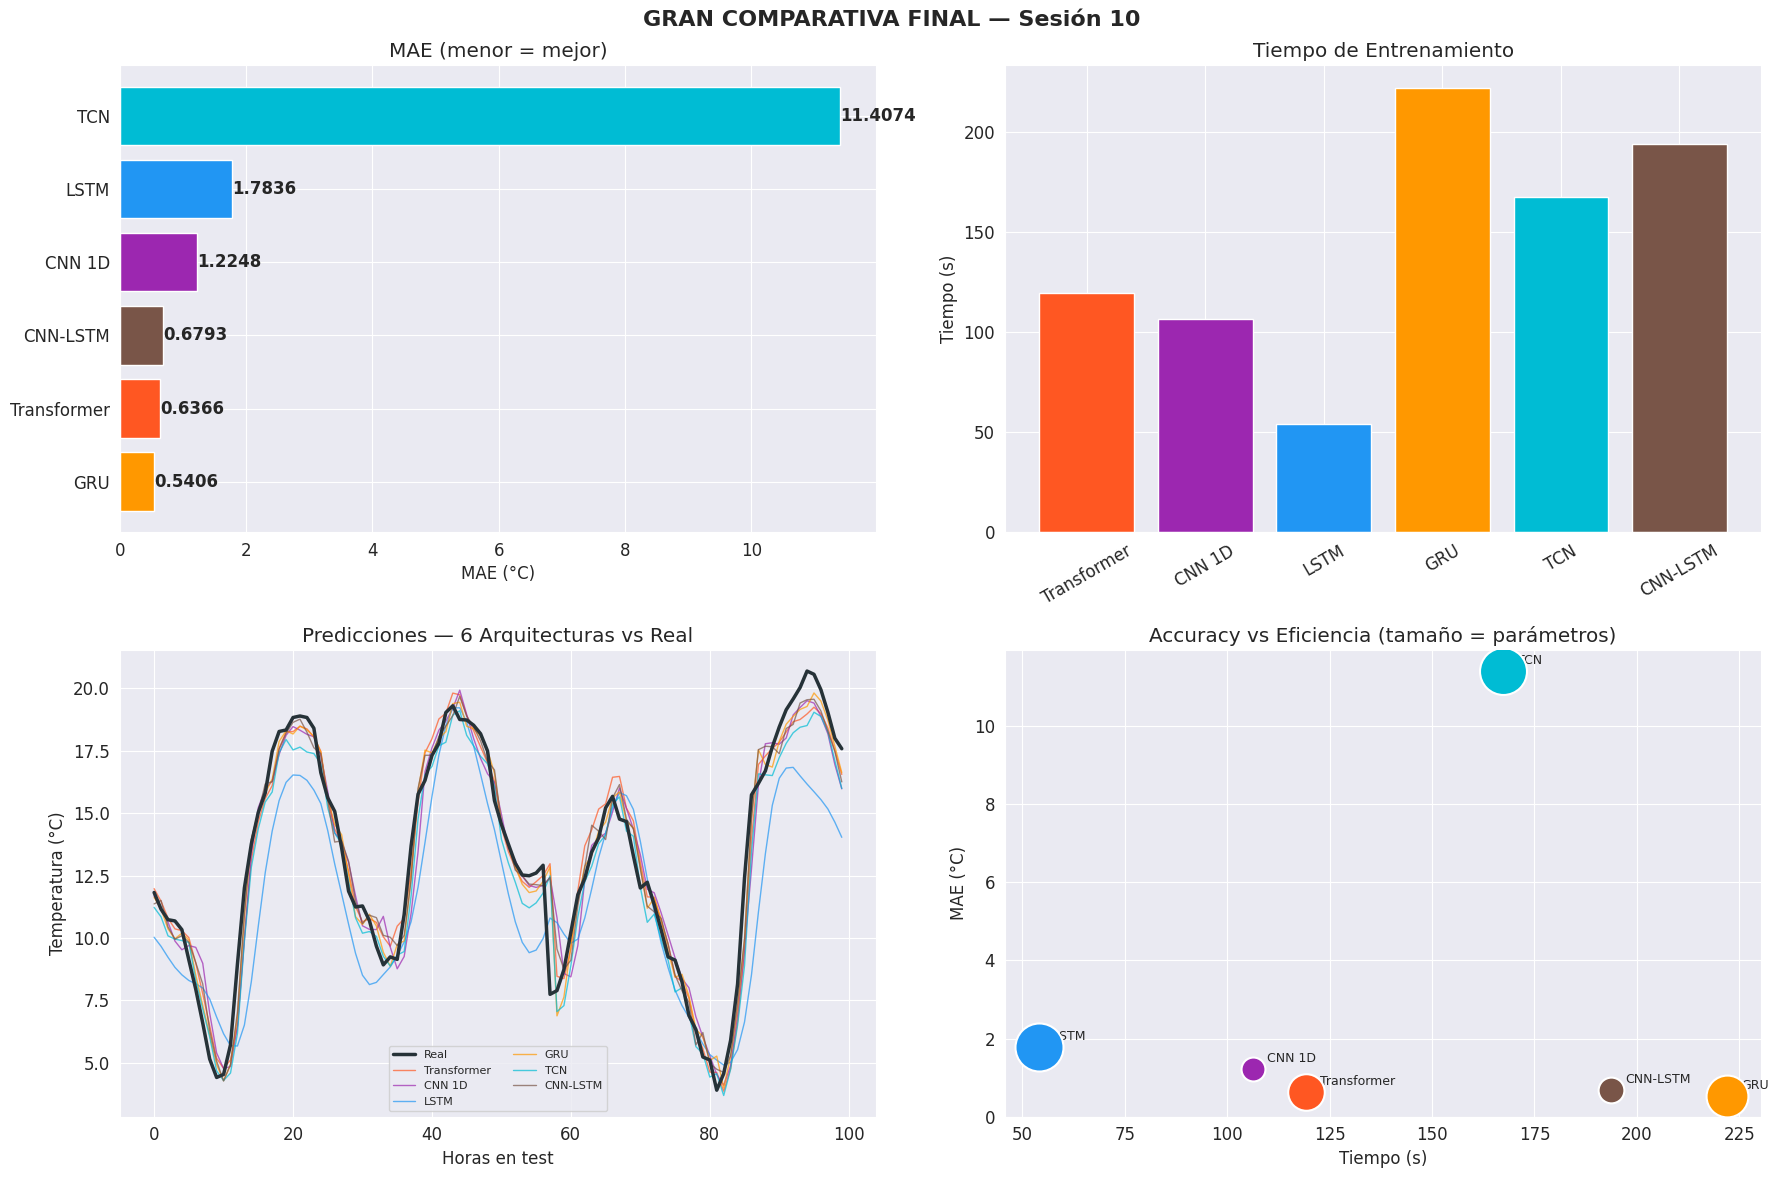

In [23]:
# ============================================================
# 📊 Visualización final — 6 modelos
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

model_names = list(benchmark_results.keys())
color_map = {
    'CNN 1D': COLORS['cnn1d'], 'LSTM': COLORS['lstm'],
    'GRU': COLORS['gru'], 'TCN': COLORS['tcn'],
    'Transformer': COLORS['transformer'], 'CNN-LSTM': COLORS['hybrid']
}

# 1. MAE horizontal bars
maes = [benchmark_results[n]['mae'] for n in model_names]
sorted_idx = np.argsort(maes)
s_names = [model_names[i] for i in sorted_idx]
s_maes = [maes[i] for i in sorted_idx]
s_colors = [color_map[n] for n in s_names]
axes[0, 0].barh(s_names, s_maes, color=s_colors, edgecolor='white')
axes[0, 0].set_xlabel('MAE (°C)'); axes[0, 0].set_title('MAE (menor = mejor)')
for i, v in enumerate(s_maes):
    axes[0, 0].text(v + 0.005, i, f'{v:.4f}', va='center', fontweight='bold')

# 2. Tiempo
times = [benchmark_results[n]['time'] for n in model_names]
axes[0, 1].bar(model_names, times, color=[color_map[n] for n in model_names], edgecolor='white')
axes[0, 1].set_ylabel('Tiempo (s)'); axes[0, 1].set_title('Tiempo de Entrenamiento')
axes[0, 1].tick_params(axis='x', rotation=30)

# 3. Predicciones
n_show = 100
axes[1, 0].plot(y_test_real[:n_show], color=COLORS['actual'], linewidth=2.5,
                label='Real', zorder=10)
for name in model_names:
    axes[1, 0].plot(benchmark_results[name]['pred'][:n_show],
                    color=color_map[name], linewidth=1, alpha=0.7, label=name)
axes[1, 0].set_xlabel('Horas en test'); axes[1, 0].set_ylabel('Temperatura (°C)')
axes[1, 0].set_title('Predicciones — 6 Arquitecturas vs Real')
axes[1, 0].legend(fontsize=8, ncol=2)

# 4. Accuracy vs Eficiencia scatter
for name in model_names:
    r = benchmark_results[name]
    axes[1, 1].scatter(r['time'], r['mae'], s=r['params']/100,
                       color=color_map[name], label=name,
                       edgecolors='white', linewidth=1.5, zorder=5)
    axes[1, 1].annotate(name, (r['time'], r['mae']),
                        textcoords="offset points", xytext=(10, 5), fontsize=9)
axes[1, 1].set_xlabel('Tiempo (s)'); axes[1, 1].set_ylabel('MAE (°C)')
axes[1, 1].set_title('Accuracy vs Eficiencia (tamaño = parámetros)')

plt.suptitle('GRAN COMPARATIVA FINAL — Sesión 10', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 💡 Conclusiones del Ejemplo 3 — Gran Comparativa

1. **No siempre gana el más complejo**: Transformer no siempre es el mejor para datasets pequeños.
2. **La preparación de datos importa más que la arquitectura**: split, normalización, ventanas.
3. **TCN y CNN 1D son sorprendentemente competitivos** — y mucho más rápidos.
4. **El híbrido CNN-LSTM** combina lo mejor: patrones locales (CNN) + dependencias largas (LSTM).
5. **GRU sigue siendo excelente** para comenzar: simple, rápido, generalmente top 3.

### 🎯 Guía de Selección Práctica

| Situación | Recomendación |
|---|---|
| Poco dato, problema simple | GRU o LSTM |
| Secuencias muy largas (>500 pasos) | TCN (campo receptivo exponencial) |
| Necesitas velocidad | CNN 1D (5-10x más rápida) |
| Mucho dato, relaciones complejas | Transformer |
| Patrones locales + dependencias largas | CNN-LSTM híbrido |
| No sabes qué usar | GRU → TCN → Transformer (orden incremental) |

---

## ✅ Checklist de Verificación — Sesión 10 Completa

| # | Concepto | Notebook 10-A | Notebook 10-B |
|---|---|---|---|
| 1 | Split cronológico | ✅ Jena Climate | ✅ Jena + Eléctrico |
| 2 | Normalización fit solo en train | ✅ | ✅ |
| 3 | Padding causal para forecasting | — | ✅ CNN1D + TCN |
| 4 | Baseline naive | ✅ | — (comparativa directa) |
| 5 | Métricas apropiadas | ✅ MAE/RMSE/F1 | ✅ MAE/RMSE + Accuracy |
| 6 | Visualización de predicciones | ✅ | ✅ |
| 7 | Comparación de arquitecturas | ✅ 4 modelos | ✅ 6 modelos |
| 8 | Interpretabilidad | ✅ Gates LSTM | ✅ Filtros CNN |
| 9 | Multi-horizonte | — | ✅ 24h adelante |
| 10 | Arquitectura híbrida | — | ✅ CNN-LSTM |

## 📋 Resumen de Resultados — Sesión 10 Completa

### Notebook 10-A (RNN, LSTM, GRU)
| Ejemplo | Tarea | Resultado Clave |
|---|---|---|
| 1 🟢 | Forecasting univariado | LSTM supera naive baseline |
| 2 🟡 | Forecasting multivariado | GRU ≈ LSTM con 25% menos params |
| 3 🔴 | Clasificación de señales | BiLSTM > todos (lee bidireccional) |

### Notebook 10-B (CNN 1D, TCN, Transformers)
| Ejemplo | Tarea | Resultado Clave |
|---|---|---|
| 1 🟢 | Clasificación con CNN 1D | Competitivo con BiLSTM, 5-10x más rápido |
| 2 🟡 | Forecasting con TCN | Campo receptivo exponencial, eficiente |
| 3 🔴 | Gran Comparativa (6 modelos) | La preparación de datos > la arquitectura |

### Lección final
> *"El mejor modelo no es el más complejo, sino el que mejor se adapta a TU problema con TUS datos."*

---

### 🔮 Siguiente: Sesión 11 — MLOps

| Tema | Descripción |
|---|---|
| **Versionado de datos** | DVC, MLflow artifacts |
| **Tracking de experimentos** | MLflow, Weights & Biases |
| **Serving de modelos** | TFServing, FastAPI, TFLite |
| **CI/CD para ML** | GitHub Actions, testing automático |
| **Monitoreo** | Concept drift, data drift, model decay |

> 🎯 **Tarea:** Seleccionar un dataset real de [Kaggle Time Series](https://www.kaggle.com/tags/time-series), aplicar al menos 3 arquitecturas (recurrente, convolucional, Transformer/híbrida), y comparar con MAE, RMSE, tiempo y parámetros.

---

*Notebook generado para el curso IS056B — Ingeniería del Conocimiento | UNCP 2026-II*
*Docente: Msc. Jaime Antonio Huaytalla Pariona*